# Graph Construction

Calls `src/graphs.py` functions. Includes SAGEConv directionality verification.
No logic lives here.

In [61]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path('..').resolve()))
import config
from src.graphs import (
    build_correlation_graph, save_correlation_samples,
    build_sector_graph, build_granger_graph,
    build_all_sector_graphs, make_pyg_data,
    run_granger_tests, run_granger_tests_cpu, run_granger_tests_gpu,
    verify_sageconv_directionality,
)

## Sector Graph

In [62]:
import json
from collections import Counter

with open("../data/raw/tickers.json") as f:
    tickers = json.load(f)
with open("../data/raw/sector_history.json") as f:
    sector_history = json.load(f)

# Build all sector graphs and save parquet
sector_graphs = build_all_sector_graphs(tickers, sector_history, range(2015, 2026))

# Node counts per sector per year
year_sector_counts = {}
for year in [2016, 2017]:
    counts = Counter(
        sector_history.get(t, {}).get(str(year))
        for t in tickers
        if sector_history.get(t, {}).get(str(year))
    )
    year_sector_counts[year] = len(counts)
    print(f"\n{year} — {len(counts)} sectors, {sum(counts.values())} nodes")
    for sector, n in sorted(counts.items(), key=lambda x: -x[1]):
        print(f"  {sector}: {n}")

# Full-universe check: 2016 should have 10 GICS sectors, 2017 should have 11
# (Real Estate split from Financials in August 2016). Skipped for dev universe.
if len(tickers) >= 400:
    assert year_sector_counts[2016] >= 10, \
        f"Expected >=10 sectors in 2016, got {year_sector_counts[2016]}"
    assert year_sector_counts[2017] >= 11, \
        f"Expected >=11 sectors in 2017, got {year_sector_counts[2017]}"
    print("\nSector count assertions passed (full universe).")

Saved 267490 total edges across 11 years to /Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/data/graphs/sector_edges_by_year.parquet

2016 — 11 sectors, 460 nodes
  Financials: 96
  Information Technology: 77
  Industrials: 66
  Health Care: 57
  Consumer Discretionary: 55
  Consumer Staples: 31
  Utilities: 29
  Energy: 20
  Materials: 18
  Telecommunication Services: 10
  Unknown: 1

2017 — 12 sectors, 460 nodes
  Information Technology: 77
  Financials: 68
  Industrials: 66
  Health Care: 57
  Consumer Discretionary: 55
  Consumer Staples: 31
  Utilities: 29
  Real Estate: 28
  Energy: 20
  Materials: 18
  Telecommunication Services: 10
  Unknown: 1

Sector count assertions passed (full universe).


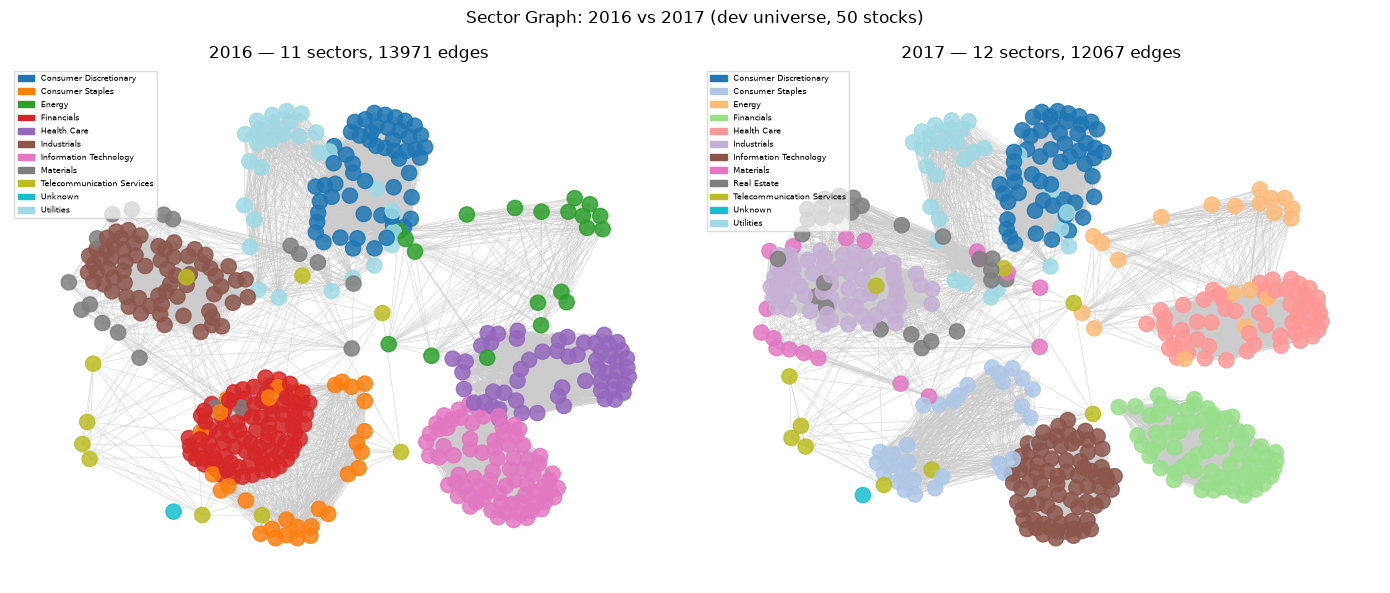

In [63]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def plot_sector_graph(tickers, sector_graphs, sector_history, year, ax):
    edge_index = sector_graphs[year]
    G = nx.Graph()
    G.add_nodes_from(range(len(tickers)))
    src = edge_index[0].tolist()
    dst = edge_index[1].tolist()
    # Add only one direction to avoid duplicate edges in undirected nx graph
    edges = {(min(s, d), max(s, d)) for s, d in zip(src, dst)}
    G.add_edges_from(edges)

    sectors = [sector_history.get(t, {}).get(str(year), "Unknown") for t in tickers]
    unique_sectors = sorted(set(sectors))
    color_map = {s: plt.cm.tab20(i / max(len(unique_sectors) - 1, 1))
                 for i, s in enumerate(unique_sectors)}
    node_colors = [color_map[s] for s in sectors]

    pos = nx.spring_layout(G, seed=config.RANDOM_SEED, k=0.6)
    nx.draw_networkx(G, pos=pos, ax=ax, node_color=node_colors,
                     node_size=120, with_labels=False, edge_color="#cccccc",
                     width=0.4, alpha=0.85)
    legend_handles = [mpatches.Patch(color=color_map[s], label=s) for s in unique_sectors]
    ax.legend(handles=legend_handles, fontsize=6, loc="upper left", framealpha=0.7)
    ax.set_title(f"{year} — {len(unique_sectors)} sectors, {G.number_of_edges()} edges")
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_sector_graph(tickers, sector_graphs, sector_history, 2016, axes[0])
plot_sector_graph(tickers, sector_graphs, sector_history, 2017, axes[1])
plt.suptitle("Sector Graph: 2016 vs 2017 (dev universe, 50 stocks)", fontsize=12)
plt.tight_layout()
plt.show()

## Correlation Graph

In [64]:
import pandas as pd

log_returns = pd.read_parquet("../data/raw/log_returns.parquet")
print(f"log_returns shape: {log_returns.shape}")
print(f"Date range: {log_returns.index[0].date()} to {log_returns.index[-1].date()}")

log_returns shape: (2764, 460)
Date range: 2015-01-05 to 2025-12-30


In [65]:
print(f"Building correlation graphs (threshold θ={config.CORR_THRESHOLD}, "
      f"lookback={config.CORR_LOOKBACK_DAYS} days):\n")
corr_samples = save_correlation_samples(log_returns, tickers)

Building correlation graphs (threshold θ=0.3, lookback=252 days):

  calm     (2017-06-30):  38202 directed edges  (19101 unique pairs)
  covid    (2020-03-13): 193246 directed edges  (96623 unique pairs)
  recent   (2023-06-30): 148168 directed edges  (74084 unique pairs)


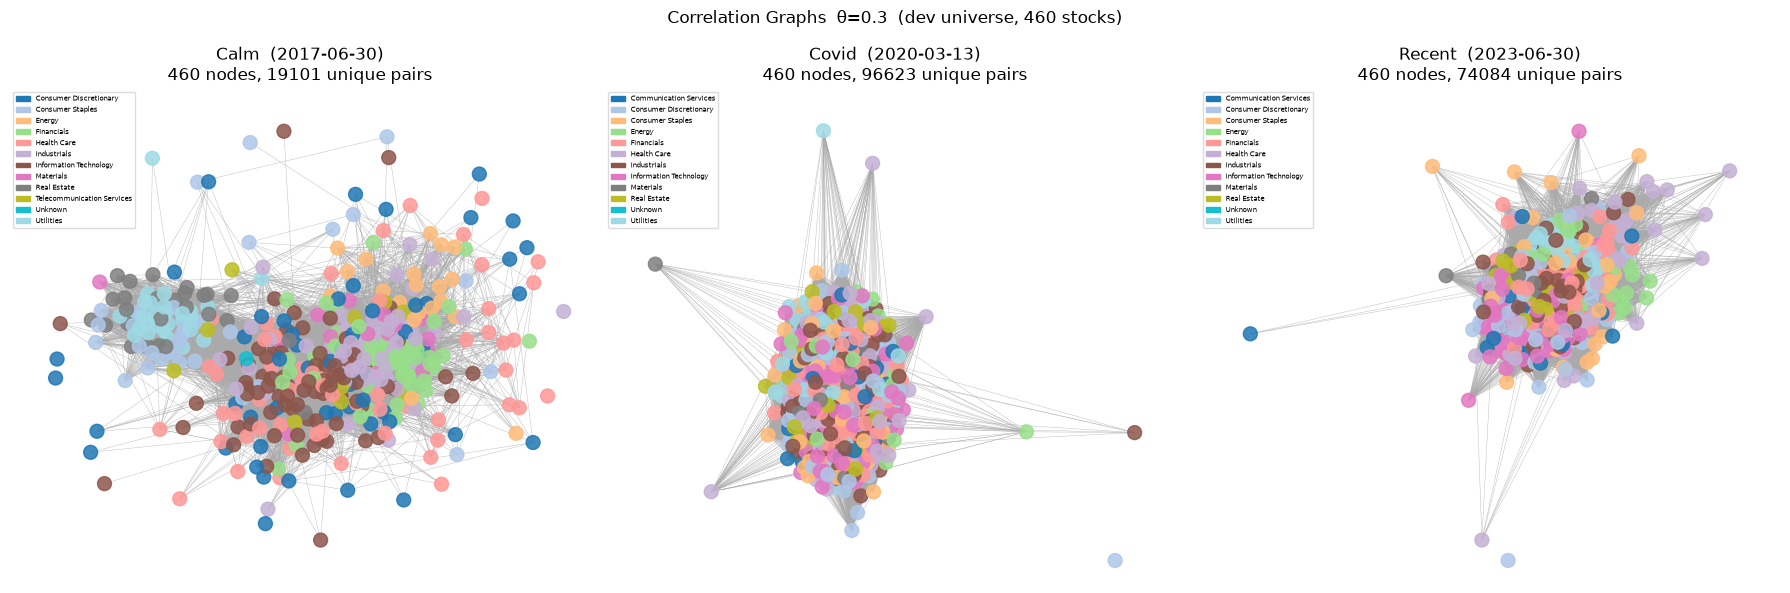

In [66]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Year used for sector coloring in each sample graph
_SAMPLE_YEARS = {"calm": 2017, "covid": 2020, "recent": 2023}

def plot_correlation_graph(edge_index, tickers, sector_history, year, ax, title):
    G = nx.Graph()
    G.add_nodes_from(range(len(tickers)))
    src = edge_index[0].tolist()
    dst = edge_index[1].tolist()
    edges = {(min(s, d), max(s, d)) for s, d in zip(src, dst)}
    G.add_edges_from(edges)

    sectors = [sector_history.get(t, {}).get(str(year), "Unknown") for t in tickers]
    unique_sectors = sorted(set(sectors))
    color_map = {s: plt.cm.tab20(i / max(len(unique_sectors) - 1, 1))
                 for i, s in enumerate(unique_sectors)}
    node_colors = [color_map[s] for s in sectors]

    pos = nx.spring_layout(G, seed=config.RANDOM_SEED, k=0.6)
    nx.draw_networkx(G, pos=pos, ax=ax, node_color=node_colors,
                     node_size=100, with_labels=False, edge_color="#aaaaaa",
                     width=0.3, alpha=0.85)
    legend_handles = [mpatches.Patch(color=color_map[s], label=s) for s in unique_sectors]
    ax.legend(handles=legend_handles, fontsize=5, loc="upper left", framealpha=0.7)
    ax.set_title(f"{title}\n{G.number_of_nodes()} nodes, {G.number_of_edges()} unique pairs")
    ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for (label, date_str), ax in zip(config.CORR_SAMPLE_DATES.items(), axes):
    plot_correlation_graph(
        corr_samples[label], tickers, sector_history,
        _SAMPLE_YEARS[label], ax,
        title=f"{label.capitalize()}  ({date_str})"
    )
plt.suptitle(f"Correlation Graphs  θ={config.CORR_THRESHOLD}  (dev universe, {len(tickers)} stocks)",
             fontsize=12)
plt.tight_layout()
plt.show()

In [67]:
calm_edges  = corr_samples["calm"].shape[1]
covid_edges = corr_samples["covid"].shape[1]
assert covid_edges > calm_edges, (
    f"Expected COVID edge count ({covid_edges}) > calm ({calm_edges})"
)
print(f"Edge count rises from calm to COVID: {calm_edges} -> {covid_edges} (confirmed)")

Edge count rises from calm to COVID: 38202 -> 193246 (confirmed)


## Granger Causality Graph

Two-step workflow — keep the steps separate so you can re-run the correction without re-running the tests:

**Step 1 — Compute p-values** (`run_granger_tests`): runs the Granger F-test for all N*(N-1) ordered stock pairs over 2015-2022 training data. Saves `data/graphs/granger_pvalues.parquet`. Takes ~5-15 min on GPU (A100), ~6-12h on CPU.

**Step 2 — Build graph** (`build_granger_graph`): loads the saved p-values, applies Bonferroni correction (falls back to BH FDR if <500 edges survive), saves `data/graphs/granger_edges.parquet`, returns directed `edge_index`.

**GPU vs CPU**: `run_granger_tests` auto-detects CUDA. On Colab with A100, it calls `run_granger_tests_gpu` which batches all N-1 unrestricted OLS fits per target stock as a single GPU operation. On CPU, it calls `run_granger_tests_cpu` which uses multiprocessing with statsmodels. Both produce the same p-values within float64 precision.

### Validate: manual F-test matches statsmodels

Runs 3 pairs through both our manual OLS formula and statsmodels on CPU. Confirms p-values agree within 1e-6 before committing to the full GPU run.

In [68]:
import numpy as np
from statsmodels.tsa.stattools import grangercausalitytests
from scipy.stats import f as f_dist

train_data = log_returns.loc[:config.TRAIN_END].dropna().values.astype(np.float64)
T, N = train_data.shape
lag = config.GRANGER_LAG
T_eff = T - lag
df1 = lag
df2 = T_eff - 2 * lag - 1  # T_eff rows minus (2*lag + 1) unrestricted params

print(f"Training data: {T} days, {N} stocks, T_eff={T_eff}, df1={df1}, df2={df2}\n")

test_pairs = [(0, 1), (5, 10), (20, 30)]  # (b_idx=target, a_idx=cause)
max_err = 0.0

for b_idx, a_idx in test_pairs:
    # statsmodels: column 0 = target B, column 1 = cause A
    data_sm = np.column_stack([train_data[:, b_idx], train_data[:, a_idx]])
    res = grangercausalitytests(data_sm, maxlag=lag)
    F_sm   = res[lag][0]["ssr_ftest"][0]
    pval_sm = res[lag][0]["ssr_ftest"][1]

    # Manual OLS matching the GPU implementation
    y = train_data[lag:, b_idx]
    B_lags = np.column_stack([train_data[lag-1-l:T-1-l, b_idx] for l in range(lag)])
    A_lags = np.column_stack([train_data[lag-1-l:T-1-l, a_idx] for l in range(lag)])
    X_r  = np.column_stack([np.ones(T_eff), B_lags])
    X_ur = np.column_stack([np.ones(T_eff), B_lags, A_lags])
    beta_r,  _, _, _ = np.linalg.lstsq(X_r,  y, rcond=None)
    beta_ur, _, _, _ = np.linalg.lstsq(X_ur, y, rcond=None)
    RSS_r  = np.sum((y - X_r  @ beta_r)  ** 2)
    RSS_ur = np.sum((y - X_ur @ beta_ur) ** 2)
    F_man  = max(0.0, ((RSS_r - RSS_ur) / df1) / (RSS_ur / df2))
    pval_man = float(f_dist.sf(F_man, df1, df2))

    err = abs(pval_sm - pval_man)
    max_err = max(max_err, err)
    print(f"  ({tickers[b_idx]}, {tickers[a_idx]})  "
          f"statsmodels p={pval_sm:.8f}  manual p={pval_man:.8f}  diff={err:.2e}")

assert max_err < 1e-6, f"Max p-value discrepancy {max_err:.2e} exceeds 1e-6"
print(f"\nAll {len(test_pairs)} pairs match statsmodels within 1e-6. GPU formula verified.")

Training data: 1887 days, 460 stocks, T_eff=1882, df1=5, df2=1871

  (A, AAPL)  statsmodels p=0.00188719  manual p=0.00188719  diff=6.23e-16
  (ACN, ADSK)  statsmodels p=0.49339855  manual p=0.49339855  diff=2.05e-13
  (ALGN, AMZN)  statsmodels p=0.08866879  manual p=0.08866879  diff=2.45e-14

All 3 pairs match statsmodels within 1e-6. GPU formula verified.


### Step 1: Compute p-values

Runs once. On GPU (A100): ~5-15 min for full universe, seconds for dev (N=50).
Saves `data/graphs/granger_pvalues.parquet` — an N×N DataFrame of p-values.

In [ ]:
import time
from pathlib import Path

pval_path = Path(config.DATA_GRAPHS_DIR) / 'granger_pvalues.parquet'
pval_df = None

if pval_path.is_file():
    existing_pvals = pd.read_parquet(pval_path)
    existing_pvals.index = existing_pvals.index.astype(str)
    existing_pvals.columns = existing_pvals.columns.astype(str)

    has_expected_tickers = (
        existing_pvals.index.is_unique
        and existing_pvals.columns.is_unique
        and set(tickers).issubset(existing_pvals.index)
        and set(tickers).issubset(existing_pvals.columns)
    )
    if has_expected_tickers:
        existing_pvals = existing_pvals.reindex(index=tickers, columns=tickers)
        values = existing_pvals.to_numpy(dtype=float)
        off_diagonal = values[~np.eye(len(tickers), dtype=bool)]
        valid_values = (
            np.isfinite(off_diagonal).all()
            and ((off_diagonal >= 0) & (off_diagonal <= 1)).all()
        )
        # The previous statsmodels call used a removed `verbose` argument;
        # its broad exception handler silently saved 1.0 for every pair.
        is_placeholder = valid_values and np.allclose(off_diagonal, 1.0)
        if valid_values and not is_placeholder:
            pval_df = existing_pvals
            print(f'Loaded valid Granger p-values: {pval_path}')
        else:
            reason = 'all off-diagonal p-values are 1.0' if is_placeholder else 'values are missing or invalid'
            print(f'Existing p-values are unusable ({reason}); recomputing them.')
    else:
        print('Existing p-value matrix has the wrong ticker labels; recomputing it.')

if pval_df is None:
    print(
        'Computing Granger p-values for the full universe. '
        'On this CPU-only system, this may take several hours.'
    )
    t0 = time.time()
    pval_df = run_granger_tests(log_returns, tickers)
    elapsed = time.time() - t0
    print(f'\nElapsed: {elapsed:.1f}s')

print(f'P-value matrix: {pval_df.shape}')
finite_pvalues = pval_df.to_numpy(dtype=float)
finite_pvalues = finite_pvalues[np.isfinite(finite_pvalues)]
print(f'Min finite p-value: {finite_pvalues.min():.2e}')
print(f'Non-null off-diagonal p-values: {np.isfinite(pval_df.to_numpy(dtype=float)[~np.eye(len(tickers), dtype=bool)]).sum():,}')


### Step 2: Build directed graph

Loads the saved p-values, applies Bonferroni correction, falls back to BH if <500 edges survive.
Saves `data/graphs/granger_edges.parquet`.

In [70]:
granger_edge_index, correction_used = build_granger_graph(tickers)

n_edges = granger_edge_index.shape[1]
n_possible = len(tickers) * (len(tickers) - 1)
density = n_edges / n_possible

print(f"Correction method : {correction_used}")
print(f"Directed edges    : {n_edges:,} / {n_possible:,} possible")
print(f"Graph density     : {density:.4f}")
print(f"edge_index shape  : {tuple(granger_edge_index.shape)}")

Bonferroni yielded 0 edges (< GRANGER_MIN_EDGES=500). Falling back to Benjamini-Hochberg FDR.
Correction: bh  |  Signal: returns  |  Edges: 0 / 211,140 pairs
Saved 0 directed edges -> /Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/data/graphs/granger_edges.parquet
Correction method : bh
Directed edges    : 0 / 211,140 possible
Graph density     : 0.0000
edge_index shape  : (2, 0)


### In/out-degree distribution

Out-degree  mean=0.0  max=0  (A — highest out-degree)
In-degree   mean=0.0  max=0  (A — highest in-degree)


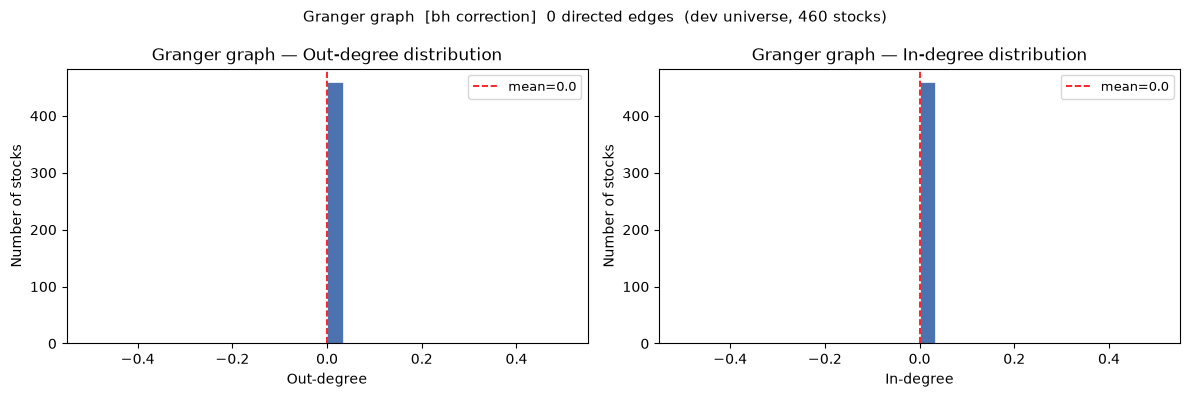

In [71]:
import matplotlib.pyplot as plt
import numpy as np

src_nodes = granger_edge_index[0].numpy()
dst_nodes = granger_edge_index[1].numpy()
N = len(tickers)

out_degree = np.bincount(src_nodes, minlength=N)
in_degree  = np.bincount(dst_nodes, minlength=N)

print(f"Out-degree  mean={out_degree.mean():.1f}  max={out_degree.max()}  "
      f"({tickers[out_degree.argmax()]} — highest out-degree)")
print(f"In-degree   mean={in_degree.mean():.1f}  max={in_degree.max()}  "
      f"({tickers[in_degree.argmax()]} — highest in-degree)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, degree, label in zip(axes, [out_degree, in_degree], ["Out-degree", "In-degree"]):
    ax.hist(degree, bins=30, color="#4c72b0", edgecolor="white", linewidth=0.5)
    ax.axvline(degree.mean(), color="red", linestyle="--", linewidth=1.2,
               label=f"mean={degree.mean():.1f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of stocks")
    ax.set_title(f"Granger graph — {label} distribution")
    ax.legend(fontsize=9)

plt.suptitle(
    f"Granger graph  [{correction_used} correction]  "
    f"{n_edges:,} directed edges  (dev universe, {N} stocks)",
    fontsize=11
)
plt.tight_layout()
plt.show()

### Directed graph — sector-colored nodes

Arrows show Granger causality direction (A → B means A's past returns predict B's). Nodes colored by 2022 sector assignment (end of training period). Edge alpha is low to keep the plot readable at high density.

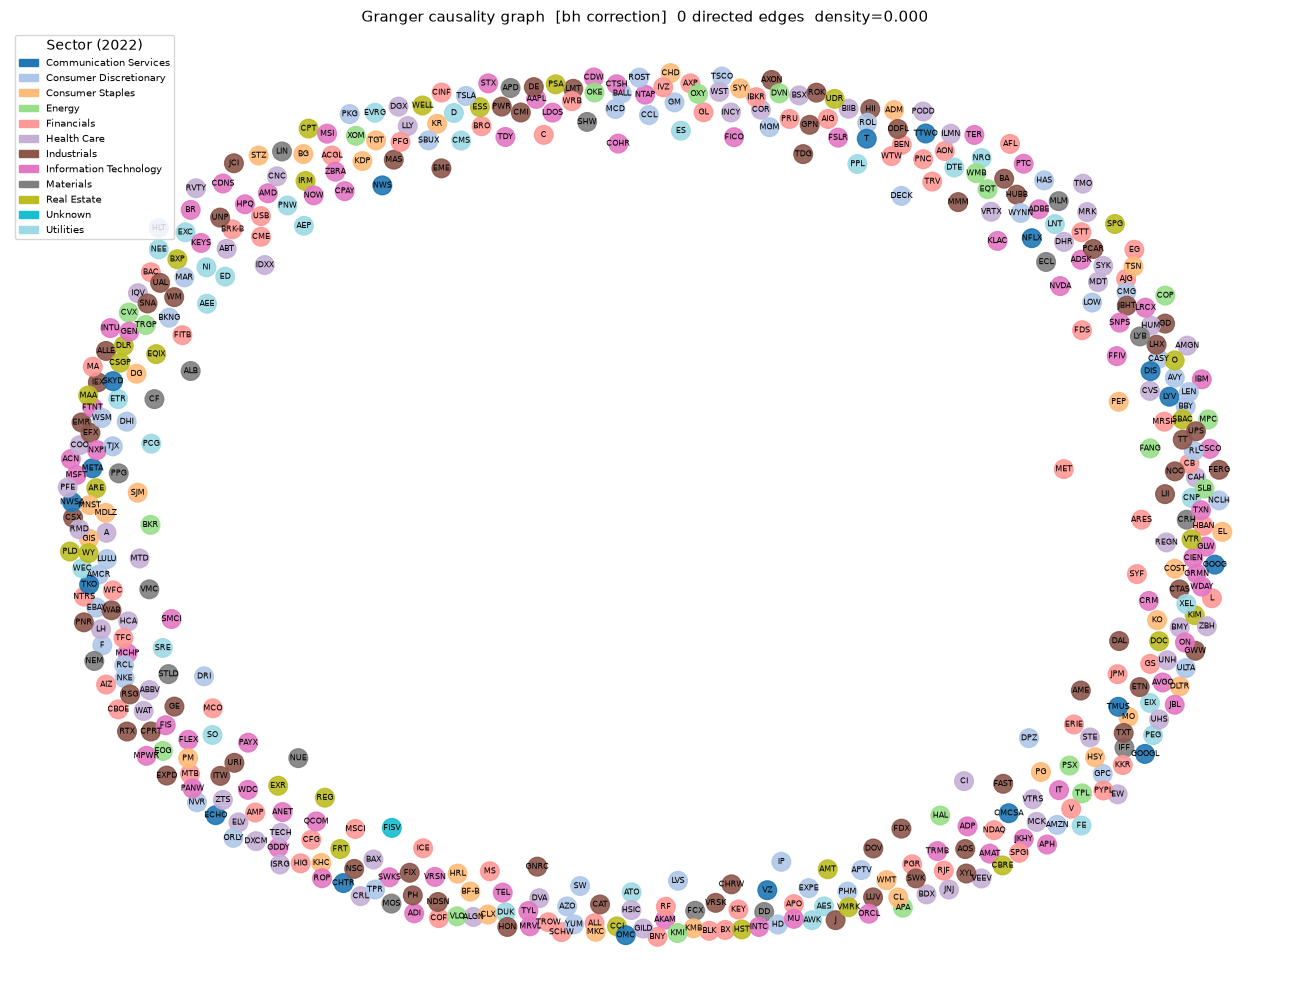

In [72]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

_GRANGER_SECTOR_YEAR = 2022  # end of training period

G = nx.DiGraph()
G.add_nodes_from(range(len(tickers)))
G.add_edges_from(zip(granger_edge_index[0].tolist(), granger_edge_index[1].tolist()))

sectors_2022 = [sector_history.get(t, {}).get(str(_GRANGER_SECTOR_YEAR), "Unknown")
                for t in tickers]
unique_sectors = sorted(set(sectors_2022))
color_map = {s: plt.cm.tab20(i / max(len(unique_sectors) - 1, 1))
             for i, s in enumerate(unique_sectors)}
node_colors = [color_map[s] for s in sectors_2022]

pos = nx.spring_layout(G, seed=config.RANDOM_SEED, k=0.7)

fig, ax = plt.subplots(figsize=(13, 10))
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=180, alpha=0.9)
nx.draw_networkx_labels(G, pos, ax=ax,
                        labels={i: t for i, t in enumerate(tickers)},
                        font_size=6, font_color="black")
nx.draw_networkx_edges(G, pos, ax=ax,
                       edge_color="#888888", alpha=0.25, width=0.6,
                       arrows=True, arrowsize=8,
                       connectionstyle="arc3,rad=0.08")  # slight curve separates A->B from B->A

legend_handles = [mpatches.Patch(color=color_map[s], label=s) for s in unique_sectors]
ax.legend(handles=legend_handles, fontsize=7, loc="upper left",
          framealpha=0.8, title="Sector (2022)")
ax.set_title(
    f"Granger causality graph  [{correction_used} correction]  "
    f"{G.number_of_edges():,} directed edges  density={density:.3f}",
    fontsize=11
)
ax.axis("off")
plt.tight_layout()
plt.show()

### P-value heatmap — sorted by sector

Each cell shows log₁₀(p-value) for the pair (row=cause A, col=target B). Darker blue = stronger Granger signal. Tickers sorted by 2022 sector so within-sector vs cross-sector patterns are visible. Diagonal is NaN (no self-test).

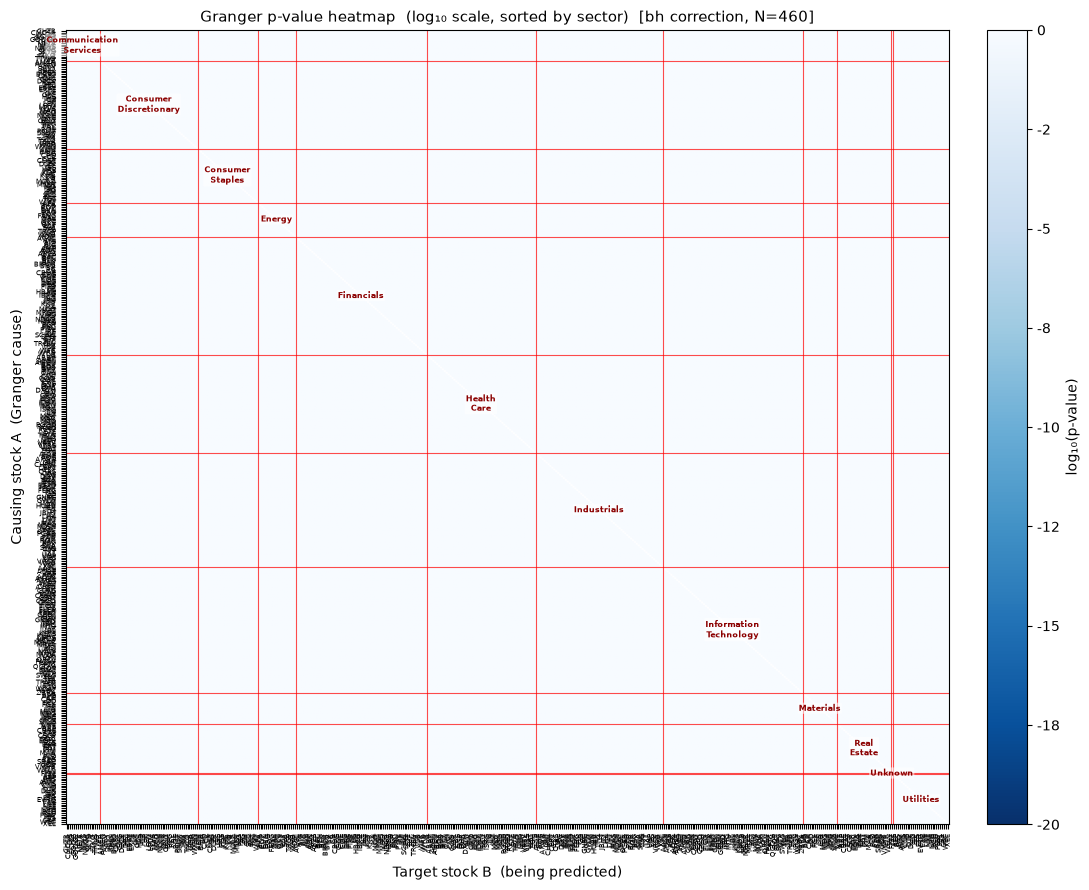

In [73]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# Sort tickers by 2022 sector, then alphabetically within sector
sector_of = {t: sector_history.get(t, {}).get("2022", "Unknown") for t in tickers}
sorted_tickers = sorted(tickers, key=lambda t: (sector_of[t], t))
sorted_idx = [tickers.index(t) for t in sorted_tickers]

# Reorder p-value matrix: rows = cause, cols = target, both sorted by sector
pval_sorted = pval_df.iloc[sorted_idx, sorted_idx].values  # (N, N)
log_pval = np.log10(np.clip(pval_sorted, 1e-20, 1.0))     # clamp to avoid -inf

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(log_pval, cmap="Blues_r", aspect="auto", vmin=-20, vmax=0)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("log₁₀(p-value)", fontsize=10)
cbar.ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f"))

# Tick labels — show ticker symbols, rotated
ax.set_xticks(range(len(sorted_tickers)))
ax.set_yticks(range(len(sorted_tickers)))
ax.set_xticklabels(sorted_tickers, rotation=90, fontsize=5)
ax.set_yticklabels(sorted_tickers, fontsize=5)
ax.set_xlabel("Target stock B  (being predicted)", fontsize=10)
ax.set_ylabel("Causing stock A  (Granger cause)", fontsize=10)

# Draw sector boundary lines
sector_labels_sorted = [sector_of[t] for t in sorted_tickers]
boundaries = []
for i in range(1, len(sector_labels_sorted)):
    if sector_labels_sorted[i] != sector_labels_sorted[i - 1]:
        boundaries.append(i - 0.5)

for b in boundaries:
    ax.axhline(b, color="red", linewidth=0.8, alpha=0.7)
    ax.axvline(b, color="red", linewidth=0.8, alpha=0.7)

# Sector name annotations along the diagonal
prev = 0
for b in boundaries + [len(sorted_tickers)]:
    mid = (prev + b - 1) / 2
    sector_name = sector_labels_sorted[prev]
    ax.text(mid, mid, sector_name.replace(" ", "\n"),
            ha="center", va="center", fontsize=5.5,
            color="darkred", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.55, ec="none"))
    prev = int(b + 0.5)

ax.set_title(
    f"Granger p-value heatmap  (log₁₀ scale, sorted by sector)  "
    f"[{correction_used} correction, N={len(tickers)}]",
    fontsize=11
)
plt.tight_layout()
plt.show()

### Top stocks by in/out-degree

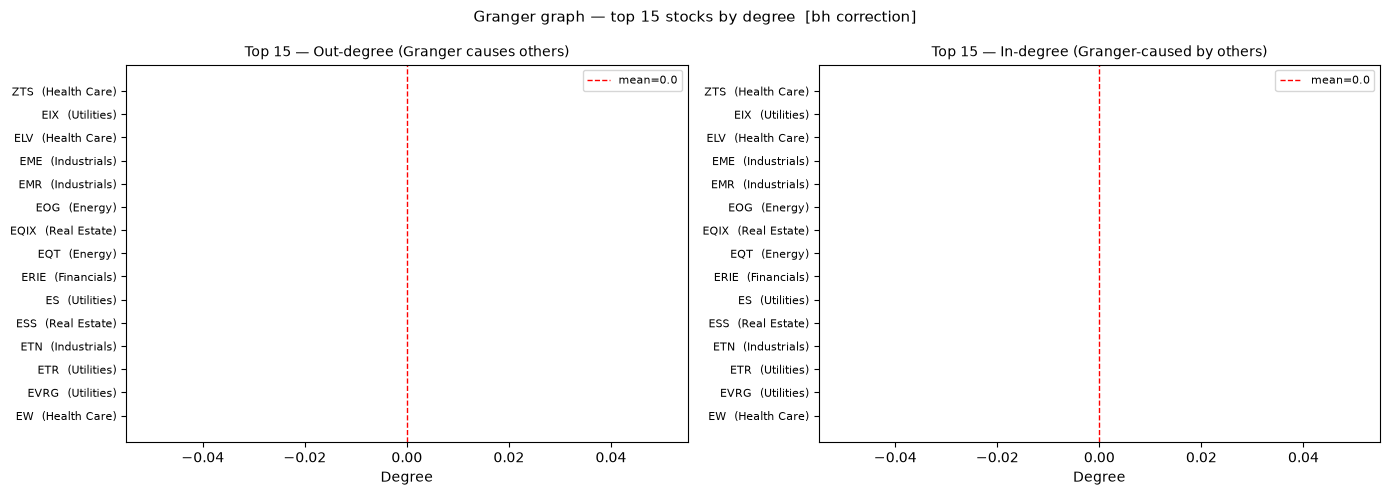

In [74]:
import matplotlib.pyplot as plt
import numpy as np

_TOP_K = 15

top_out_idx = np.argsort(out_degree)[::-1][:_TOP_K]
top_in_idx  = np.argsort(in_degree)[::-1][:_TOP_K]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, idx, degree, label, color in zip(
    axes,
    [top_out_idx, top_in_idx],
    [out_degree, in_degree],
    ["Out-degree (Granger causes others)", "In-degree (Granger-caused by others)"],
    ["#4c72b0", "#dd8452"],
):
    names  = [tickers[i] for i in idx]
    values = [degree[i] for i in idx]
    sectors_bar = [sector_of.get(t, "?") for t in names]

    bars = ax.barh(range(_TOP_K), values[::-1], color=color, alpha=0.8)
    ax.set_yticks(range(_TOP_K))
    ax.set_yticklabels(
        [f"{t}  ({s})" for t, s in zip(names[::-1], sectors_bar[::-1])],
        fontsize=8
    )
    ax.set_xlabel("Degree", fontsize=10)
    ax.set_title(f"Top {_TOP_K} — {label}", fontsize=10)
    ax.axvline(degree.mean(), color="red", linestyle="--", linewidth=1,
               label=f"mean={degree.mean():.1f}")
    ax.legend(fontsize=8)

plt.suptitle(
    f"Granger graph — top {_TOP_K} stocks by degree  [{correction_used} correction]",
    fontsize=11
)
plt.tight_layout()
plt.show()

## SAGEConv Directionality Verification

Confirms that `SAGEConv(flow="source_to_target")` produces different outputs when edge directions are reversed. This is a prerequisite for GNN-Granger training: if outputs are identical under edge reversal, SAGEConv is symmetrizing the adjacency internally and the directed Granger graph would be treated as undirected.

Test graph: 10 nodes, 12 asymmetric directed edges (chain 0→1→…→9 plus skip connections). No edge goes both ways. Same node features, same weights — only the edge direction changes between the two forward passes.

In [75]:
result = verify_sageconv_directionality()

print(f"flow direction : {result['flow']}")
print(f"test graph     : {result['num_nodes']} nodes, {result['num_edges']} directed edges")
print(f"max |out_fwd - out_rev| : {result['max_abs_diff']:.6f}")
print()
if result["passed"]:
    print("PASSED — SAGEConv respects edge direction.")
    print("GNN-Granger training may proceed with directed Granger edge_index.")
else:
    print("FAILED — SAGEConv is symmetrizing edges. Investigate before training.")

flow direction : source_to_target
test graph     : 10 nodes, 12 directed edges
max |out_fwd - out_rev| : 3.248902

PASSED — SAGEConv respects edge direction.
GNN-Granger training may proceed with directed Granger edge_index.


## Graph Statistics and Visualization

In [76]:
import importlib, src.graphs as _g; importlib.reload(_g)
from src.graphs import compute_graph_stats
import pandas as pd

N = len(tickers)
_DATE_YEARS = {"calm": 2017, "covid": 2020, "recent": 2023}

rows = []

# Correlation — dynamic, one row per sample date
for label, date_str in config.CORR_SAMPLE_DATES.items():
    s = compute_graph_stats(corr_samples[label], N, directed=False)
    rows.append({
        "Graph":       "Correlation",
        "Period":      f"{label} ({date_str})",
        "Nodes":       s["num_nodes"],
        "Edges":       s["num_edges"],
        "Density":     f"{s['density']:.4f}",
        "Mean Degree": f"{s['mean_degree']:.1f}",
        "Max Degree":  s["max_degree"],
    })

# Sector — annual, one row per year
for label, year in _DATE_YEARS.items():
    s = compute_graph_stats(sector_graphs[year], N, directed=False)
    rows.append({
        "Graph":       "Sector",
        "Period":      f"{label} ({year})",
        "Nodes":       s["num_nodes"],
        "Edges":       s["num_edges"],
        "Density":     f"{s['density']:.4f}",
        "Mean Degree": f"{s['mean_degree']:.1f}",
        "Max Degree":  s["max_degree"],
    })

# Granger — static, one row
s = compute_graph_stats(granger_edge_index, N, directed=True)
rows.append({
    "Graph":       f"Granger [{correction_used}]",
    "Period":      "static (train 2015-2022)",
    "Nodes":       s["num_nodes"],
    "Edges":       s["num_edges"],
    "Density":     f"{s['density']:.4f}",
    "Mean Degree": f"out={s['mean_out_degree']:.1f} / in={s['mean_in_degree']:.1f}",
    "Max Degree":  f"out={s['max_out_degree']} / in={s['max_in_degree']}",
})

df_stats = pd.DataFrame(rows)
print(df_stats.to_string(index=False))

       Graph                   Period  Nodes  Edges Density      Mean Degree   Max Degree
 Correlation        calm (2017-06-30)    460  19101  0.1809             83.0          244
 Correlation       covid (2020-03-13)    460  96623  0.9153            420.1          453
 Correlation      recent (2023-06-30)    460  74084  0.7018            322.1          444
      Sector              calm (2017)    460  12067  0.1143             52.5           76
      Sector             covid (2020)    460  11667  0.1105             50.7           72
      Sector            recent (2023)    460  11667  0.1105             50.7           72
Granger [bh] static (train 2015-2022)    460      0  0.0000 out=0.0 / in=0.0 out=0 / in=0


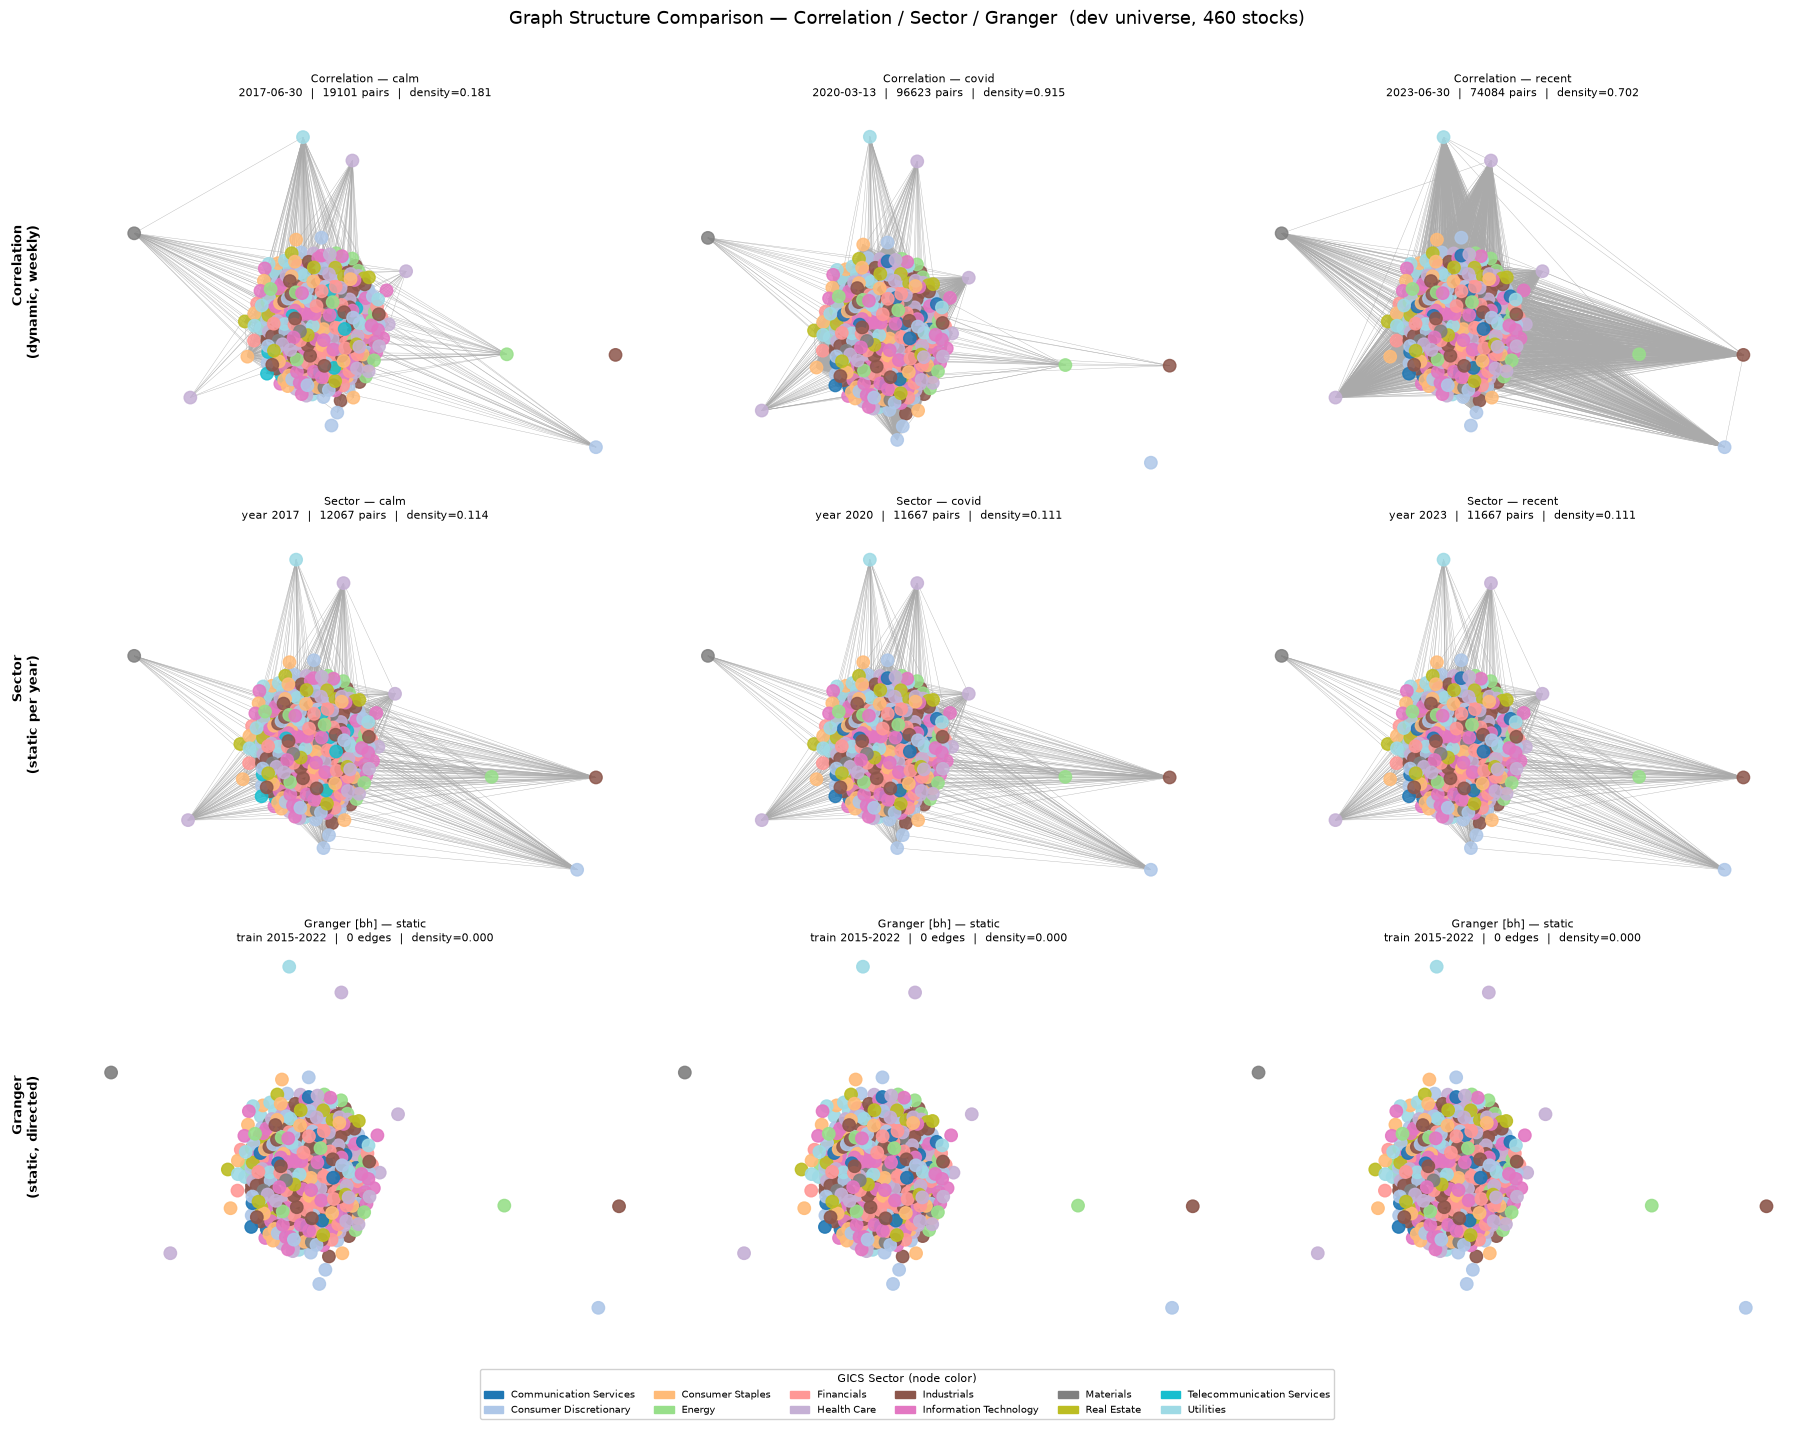

Saved -> /Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/data/results/figures/graph_comparison.png


In [77]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

os.makedirs(config.FIGURES_DIR, exist_ok=True)

N = len(tickers)
_DATE_YEARS = {"calm": 2017, "covid": 2020, "recent": 2023}

# Compute shared node positions from the COVID correlation graph (densest graph).
# Using a fixed graph for position fitting means all 9 panels share the same layout,
# making cross-panel comparisons visually direct.
G_pos = nx.Graph()
G_pos.add_nodes_from(range(N))
ei_covid = corr_samples["covid"]
G_pos.add_edges_from(
    {(min(s, d), max(s, d)) for s, d in zip(ei_covid[0].tolist(), ei_covid[1].tolist())}
)
pos = nx.spring_layout(G_pos, seed=config.RANDOM_SEED, k=0.6)

# Build a single color map covering all sector labels across all years used
all_sectors = sorted({
    sector_history.get(t, {}).get(str(yr), "Unknown")
    for yr in list(_DATE_YEARS.values()) + [2022]
    for t in tickers
} - {"Unknown"})
color_map = {s: plt.cm.tab20(i / max(len(all_sectors) - 1, 1)) for i, s in enumerate(all_sectors)}
color_map["Unknown"] = (0.7, 0.7, 0.7, 1.0)

def _node_colors(year):
    return [
        color_map.get(sector_history.get(t, {}).get(str(year), "Unknown"), (0.7, 0.7, 0.7, 1.0))
        for t in tickers
    ]

date_items = list(config.CORR_SAMPLE_DATES.items())
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for col, (label, date_str) in enumerate(date_items):
    year = _DATE_YEARS[label]

    # ── Row 0: Correlation ────────────────────────────────────────────────────
    ax = axes[0, col]
    ei = corr_samples[label]
    G = nx.Graph()
    G.add_nodes_from(range(N))
    G.add_edges_from(
        {(min(s, d), max(s, d)) for s, d in zip(ei[0].tolist(), ei[1].tolist())}
    )
    nx.draw_networkx(G, pos=pos, ax=ax, node_color=_node_colors(year),
                     node_size=80, with_labels=False,
                     edge_color="#aaaaaa", width=0.3, alpha=0.85)
    n_pairs = ei.shape[1] // 2
    ax.set_title(
        f"Correlation — {label}\n{date_str}  |  {n_pairs} pairs  |  density={n_pairs/(N*(N-1)//2):.3f}",
        fontsize=8
    )
    ax.axis("off")

    # ── Row 1: Sector ─────────────────────────────────────────────────────────
    ax = axes[1, col]
    ei = sector_graphs[year]
    G = nx.Graph()
    G.add_nodes_from(range(N))
    G.add_edges_from(
        {(min(s, d), max(s, d)) for s, d in zip(ei[0].tolist(), ei[1].tolist())}
    )
    nx.draw_networkx(G, pos=pos, ax=ax, node_color=_node_colors(year),
                     node_size=80, with_labels=False,
                     edge_color="#aaaaaa", width=0.3, alpha=0.85)
    n_pairs = ei.shape[1] // 2
    ax.set_title(
        f"Sector — {label}\nyear {year}  |  {n_pairs} pairs  |  density={n_pairs/(N*(N-1)//2):.3f}",
        fontsize=8
    )
    ax.axis("off")

    # ── Row 2: Granger (static — identical panel for all three columns) ───────
    ax = axes[2, col]
    G = nx.DiGraph()
    G.add_nodes_from(range(N))
    G.add_edges_from(
        zip(granger_edge_index[0].tolist(), granger_edge_index[1].tolist())
    )
    # Node color from 2022 sector (end of training period)
    nx.draw_networkx_nodes(G, pos=pos, ax=ax, node_color=_node_colors(2022),
                           node_size=80, alpha=0.9)
    nx.draw_networkx_edges(G, pos=pos, ax=ax,
                           edge_color="#888888", alpha=0.2, width=0.3,
                           arrows=True, arrowsize=5,
                           connectionstyle="arc3,rad=0.08")
    n_edges = granger_edge_index.shape[1]
    ax.set_title(
        f"Granger [{correction_used}] — static\ntrain 2015-2022  |  {n_edges} edges  |  density={n_edges/(N*(N-1)):.3f}",
        fontsize=8
    )
    ax.axis("off")

# Row labels (outside left edge of each row)
for row_idx, row_name in enumerate([
    "Correlation\n(dynamic, weekly)",
    "Sector\n(static per year)",
    f"Granger\n(static, directed)",
]):
    axes[row_idx, 0].text(
        -0.08, 0.5, row_name,
        transform=axes[row_idx, 0].transAxes,
        fontsize=9, fontweight="bold", va="center", ha="right", rotation=90,
    )

# Shared sector legend below the figure
legend_handles = [mpatches.Patch(color=color_map[s], label=s) for s in all_sectors]
fig.legend(
    handles=legend_handles, fontsize=7, loc="lower center",
    ncol=min(len(all_sectors), 6), framealpha=0.9,
    title="GICS Sector (node color)", title_fontsize=8,
    bbox_to_anchor=(0.5, 0.0),
)

plt.suptitle(
    f"Graph Structure Comparison — Correlation / Sector / Granger  (dev universe, {N} stocks)",
    fontsize=13, y=1.01,
)
plt.tight_layout(rect=[0, 0.06, 1, 1])

out_path = os.path.join(config.FIGURES_DIR, "graph_comparison.png")
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {out_path}")

In [78]:
import importlib, src.graphs as _g; importlib.reload(_g)
from src.graphs import make_pyg_data
import torch

N = len(tickers)
num_features = 10  # arbitrary dimension for shape testing
dummy_x = torch.randn(N, num_features)
dummy_y = torch.randn(N)

checks = [
    ("Correlation (calm)",   corr_samples["calm"],   False),
    ("Correlation (covid)",  corr_samples["covid"],  False),
    ("Correlation (recent)", corr_samples["recent"], False),
    ("Sector (2017)",        sector_graphs[2017],    False),
    ("Sector (2020)",        sector_graphs[2020],    False),
    ("Sector (2023)",        sector_graphs[2023],    False),
    ("Granger (directed)",   granger_edge_index,     True),
]

for name, ei, directed in checks:
    data = make_pyg_data(dummy_x, ei, dummy_y)
    assert data.x.shape == (N, num_features)
    assert data.y.shape == (N,)
    assert data.edge_index.shape[0] == 2
    if ei.shape[1] > 0:
        assert int(data.edge_index.max()) < N
    print(f"  {name:28s}  edge_index={tuple(data.edge_index.shape)}")

print(f"\nAll {len(checks)} PyG Data objects constructed and verified.")

  Correlation (calm)            edge_index=(2, 38202)
  Correlation (covid)           edge_index=(2, 193246)
  Correlation (recent)          edge_index=(2, 148168)
  Sector (2017)                 edge_index=(2, 24134)
  Sector (2020)                 edge_index=(2, 23334)
  Sector (2023)                 edge_index=(2, 23334)
  Granger (directed)            edge_index=(2, 0)

All 7 PyG Data objects constructed and verified.


## Correlation graph-density diagnostics

<!-- STEP5_GRAPH_DIAGNOSTICS -->

/var/folders/4n/9vhf3yqn3pj0dt94ktyqrq080000gn/T/ipykernel_27034/3998212929.py:28: UserWarning: build_correlation_graph: fewer than requested rows available — correlation estimated on a shorter window (expected at dataset start).
  edge_index = build_correlation_graph(


### Correlation Graph Density Summary

num_edges                        density                          \
             mean   median    min    max    mean  median     min     max   
split                                                                      
test   35331.1650  27983.0  18564  54673  0.3347  0.2651  0.1758  0.5179   
train  57362.7074  56931.0      0  99849  0.5434  0.5393  0.0000  0.9458   
val    71396.7308  74784.5  40900  86316  0.6763  0.7084  0.3874  0.8176   

      mean_degree                               max_degree                   \
             mean    median       min       max       mean median  min  max   
split                                                                         
test     153.6138  121.6652   80.7130  237.7087   325.2233  308.0  223  413   
train    249.4031  247.5261    0.0000  434.1261   386.4436  405.0    0  458   
val      310.4206  325.1500  177.8261  375.2870   434.4615  445.5  356  456   

      avg_abs_correlation                          
                     mean  median     min     max  
split                                              
test               0.4106  0.3974  0.3924  0.4434  
train              0.4488  0.4340  0.0000  0.7203  
val                0.4525  0.4539  0.4037  0.4871

### Density Quantiles by Split

,p05,p25,median,p75,p95
split,,,,,
test,0.1871,0.2236,0.2651,0.4884,0.5152
train,0.1547,0.3647,0.5393,0.7112,0.9313
val,0.4109,0.6079,0.7084,0.7846,0.8142


...

,num_edges,density,mean_degree,max_degree,avg_abs_correlation
mean,35331.165,0.3347,153.6138,325.2233,0.4106
median,27983.000,0.2651,121.6652,308.0000,0.3974
min,18564.000,0.1758,80.7130,223.0000,0.3924
max,54673.000,0.5179,237.7087,413.0000,0.4434


### Example Test Weeks: Lowest, Highest, and Recent Density

/var/folders/4n/9vhf3yqn3pj0dt94ktyqrq080000gn/T/ipykernel_27034/3998212929.py:112: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(example_weeks[['example', 'week', 'num_edges', 'density', 'mean_degree', 'max_degree', 'avg_abs_correlation']].round(4))


,example,week,num_edges,density,mean_degree,max_degree,avg_abs_correlation
0,lowest density,2024-12-16,18564,0.1758,80.7130,223,0.3941
1,lowest density,2025-02-24,19090,0.1808,83.0000,242,0.3951
2,lowest density,2025-02-17,19163,0.1815,83.3174,243,0.3949
3,lowest density,2024-12-09,19355,0.1833,84.1522,232,0.3962
4,lowest density,2025-03-03,19444,0.1842,84.5391,241,0.3952
5,highest density,2025-05-26,54673,0.5179,237.7087,408,0.4382
6,highest density,2025-07-07,54606,0.5172,237.4174,411,0.4434
7,highest density,2025-07-21,54574,0.5169,237.2783,413,0.4429
8,highest density,2025-06-30,54565,0.5169,237.2391,411,0.4423
9,highest density,2025-07-28,54472,0.5160,236.8348,412,0.4418


### Paper-Ready Sentence Options\n- During the test period, the rolling correlation graph at threshold 0.30 had average density 0.335, ranging from 0.176 on 2024-12-16 to 0.518 on 2025-05-26.\n- In edge-count terms, the test graph averaged 35,331 undirected edges, with a low of 18,564 and a high of 54,673.\n- The mean degree averaged 153.6 during the test period, peaking at 237.7 in the densest week, which supports the oversmoothing limitation: during highly correlated regimes, each node aggregates information from many more neighbors.

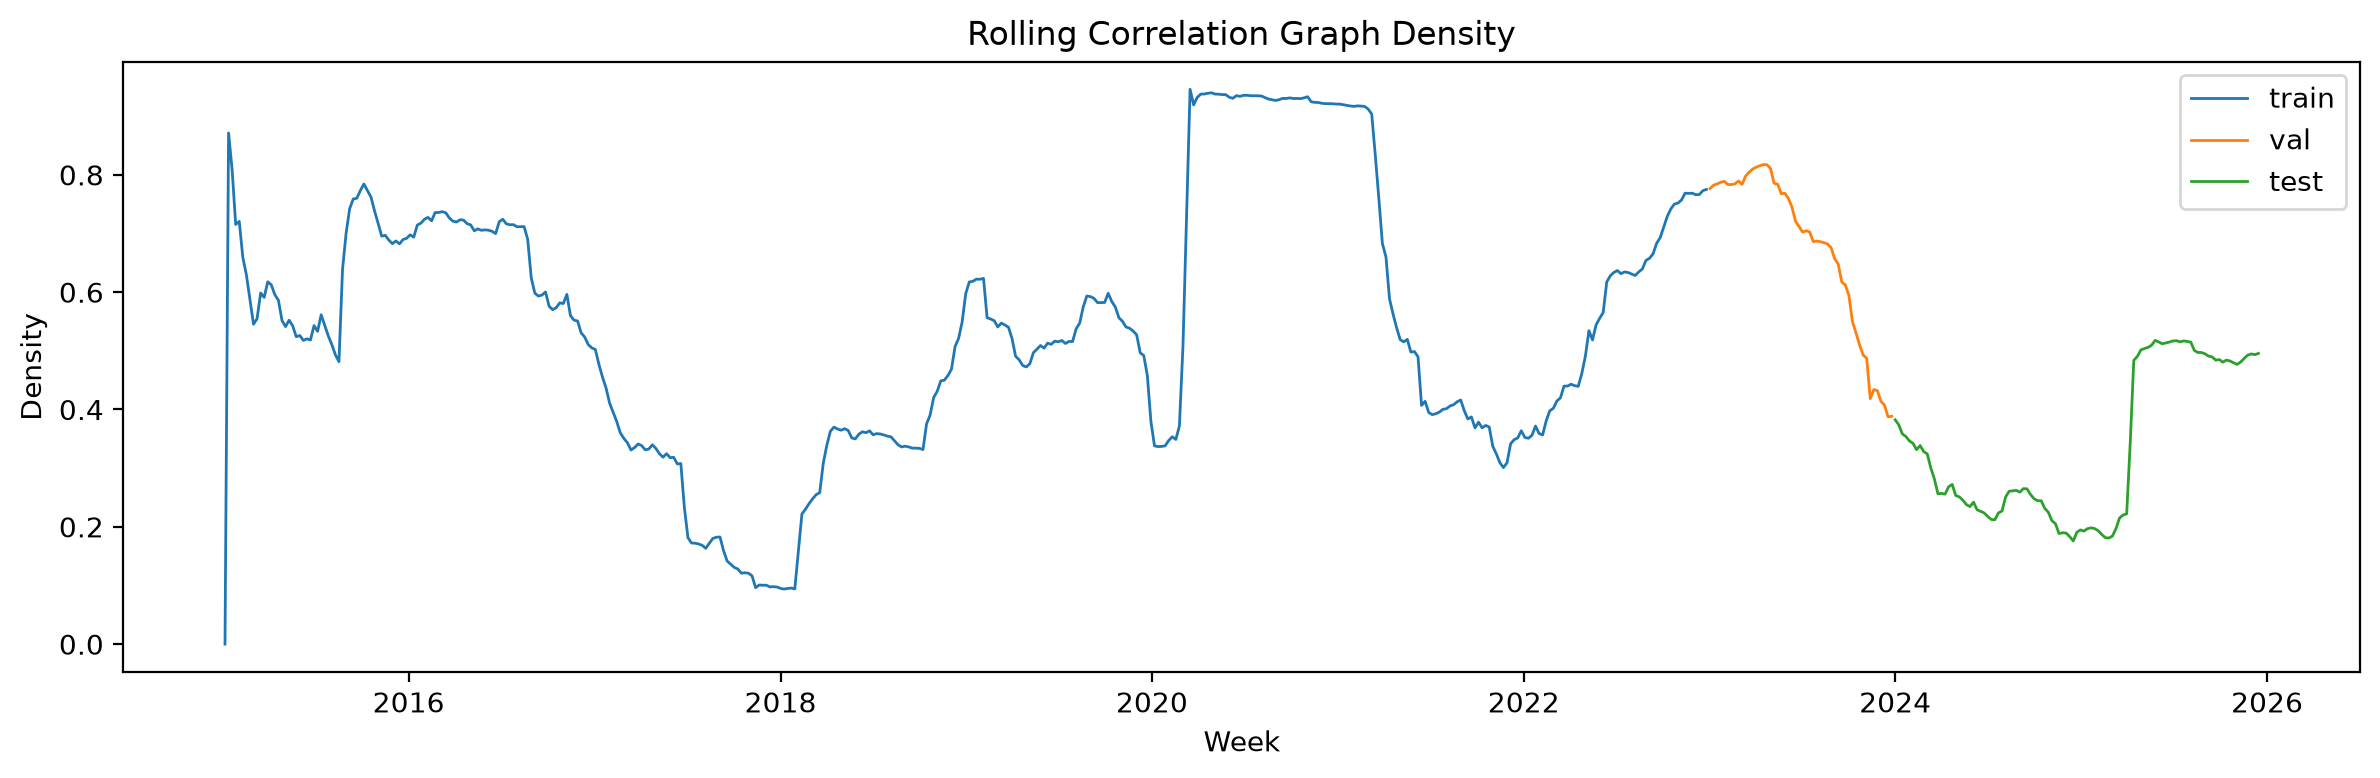

In [79]:
# STEP5_GRAPH_DIAGNOSTICS_TABLE
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, display, Image

results_dir = Path('../data/results')
figures_dir = results_dir / 'figures'
density_path = results_dir / 'correlation_graph_density.csv'
density_figure_path = figures_dir / 'correlation_graph_density.png'

if density_path.exists():
    density = pd.read_csv(density_path, parse_dates=['week'])
else:
    splits = pd.read_parquet('../data/features/splits.parquet')
    if 'split' not in splits.columns:
        raise ValueError("splits.parquet must contain a 'split' column.")

    week_col = next((col for col in ('week', 'date') if col in splits.columns), None)
    if week_col is None:
        if not isinstance(splits.index, pd.DatetimeIndex):
            raise ValueError("splits.parquet needs a 'week'/'date' column or a DatetimeIndex.")
        weeks = splits.index
    else:
        weeks = pd.to_datetime(splits[week_col])

    rows = []
    for week, split in zip(weeks, splits['split']):
        edge_index = build_correlation_graph(
            log_returns, pd.Timestamp(week),
            config.CORR_LOOKBACK_DAYS, config.CORR_THRESHOLD
        )
        edges = edge_index.detach().cpu().numpy()
        pairs = np.unique(np.sort(edges.T, axis=1), axis=0) if edges.shape[1] else np.empty((0, 2), dtype=int)

        n_nodes = len(tickers)
        degrees = np.bincount(pairs.ravel(), minlength=n_nodes)
        corr_window = log_returns.loc[:week].tail(config.CORR_LOOKBACK_DAYS)
        corr = corr_window.corr().to_numpy()
        avg_abs_corr = (
            np.abs(corr[pairs[:, 0], pairs[:, 1]]).mean()
            if len(pairs) else 0.0
        )
        n_pairs = len(pairs)

        rows.append({
            'week': pd.Timestamp(week),
            'split': split,
            'threshold': config.CORR_THRESHOLD,
            'num_edges': n_pairs,
            'density': n_pairs / (n_nodes * (n_nodes - 1) / 2),
            'mean_degree': 2 * n_pairs / n_nodes,
            'max_degree': int(degrees.max()) if n_nodes else 0,
            'avg_abs_correlation': avg_abs_corr,
        })

    density = pd.DataFrame(rows).sort_values('week')
    results_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)
    density.to_csv(density_path, index=False)

    fig, ax = plt.subplots(figsize=(12, 4))
    for split, group in density.groupby('split', sort=False):
        ax.plot(group['week'], group['density'], label=split, linewidth=1)
    ax.set(title='Rolling Correlation Graph Density', xlabel='Week', ylabel='Density')
    ax.legend()
    fig.tight_layout()
    fig.savefig(density_figure_path, dpi=200, bbox_inches='tight')
    plt.close(fig)
official = density[density['threshold'].eq(config.CORR_THRESHOLD)].copy()

metric_cols = ['num_edges', 'density', 'mean_degree', 'max_degree', 'avg_abs_correlation']
summary_by_split = (
    official.groupby('split')[metric_cols]
    .agg(['mean', 'median', 'min', 'max'])
    .round(4)
)
summary_by_split.to_csv(results_dir / 'correlation_graph_density_summary_by_split.csv')

quantiles_by_split = (
    official.groupby('split')['density']
    .quantile([0.05, 0.25, 0.50, 0.75, 0.95])
    .unstack()
    .rename(columns={0.05: 'p05', 0.25: 'p25', 0.50: 'median', 0.75: 'p75', 0.95: 'p95'})
    .round(4)
)
quantiles_by_split.to_csv(results_dir / 'correlation_graph_density_quantiles_by_split.csv')

test_density = official[official['split'].eq('test')].sort_values('week').copy()
test_summary = test_density[metric_cols].agg(['mean', 'median', 'min', 'max']).round(4)
test_summary.to_csv(results_dir / 'correlation_graph_density_test_summary.csv')

example_weeks = pd.concat(
    [
        test_density.nsmallest(5, 'density').assign(example='lowest density'),
        test_density.nlargest(5, 'density').assign(example='highest density'),
        test_density.tail(10).assign(example='recent test weeks'),
    ],
    ignore_index=True,
).drop_duplicates(['week', 'split', 'threshold'])
example_weeks.to_csv(results_dir / 'correlation_graph_density_paper_examples.csv', index=False)

display(Markdown('### Correlation Graph Density Summary'))
display(summary_by_split)

display(Markdown('### Density Quantiles by Split'))
display(quantiles_by_split)

display(Markdown('### Test-Period Summary for Paper Reporting'))
display(test_summary)

display(Markdown('### Example Test Weeks: Lowest, Highest, and Recent Density'))
display(example_weeks[['example', 'week', 'num_edges', 'density', 'mean_degree', 'max_degree', 'avg_abs_correlation']].round(4))

test_mean = test_density['density'].mean()
test_min_row = test_density.loc[test_density['density'].idxmin()]
test_max_row = test_density.loc[test_density['density'].idxmax()]
display(Markdown(
    '### Paper-Ready Sentence Options\\n'
    f'- During the test period, the rolling correlation graph at threshold {config.CORR_THRESHOLD:.2f} '
    f'had average density {test_mean:.3f}, ranging from {test_min_row["density"]:.3f} '
    f'on {test_min_row["week"].date()} to {test_max_row["density"]:.3f} on {test_max_row["week"].date()}.\\n'
    f'- In edge-count terms, the test graph averaged {test_density["num_edges"].mean():,.0f} undirected edges, '
    f'with a low of {int(test_min_row["num_edges"]):,} and a high of {int(test_max_row["num_edges"]):,}.\\n'
    f'- The mean degree averaged {test_density["mean_degree"].mean():.1f} during the test period, '
    f'peaking at {test_max_row["mean_degree"]:.1f} in the densest week, which supports the oversmoothing limitation: '
    'during highly correlated regimes, each node aggregates information from many more neighbors.'
))

display(Image(filename=str(figures_dir / 'correlation_graph_density.png')))